<a href="https://colab.research.google.com/github/fatma-kchaou/Seq2Seq/blob/main/T_automatique_Seq2Seqnotebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IA générative (IIT 2026-2027)**
## Traduction automatique Seq2Seq en PyTorch

---

**Objectif de l'atelier :** construire pas à pas un modèle **Encoder–Decoder avec LSTM** pour traduire une phrase anglaise vers le français.

Vous devez comprendre :

- comment construire un vocabulaire ;
- comment transformer une phrase en indices ;
- comment préparer les données pour un modèle séquentiel ;
- le rôle de l'**Encoder**, du **Decoder**, de `hidden` et `cell` ;
- pourquoi la cible est décalée pendant l'entraînement ;
- comment entraîner puis utiliser le modèle pour générer une traduction.



**Importation des modules**



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from tqdm import tqdm
import pandas as pd
import math

from torch.utils.data import TensorDataset, DataLoader
from collections import Counter
from sklearn.model_selection import train_test_split



In [ ]:
# Assemblage Google Drive dans Colaboratory
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<strong><u><span>1/Chargement des données à partir du fichier **data_seq2seq.csv**</span></u></strong>

Le fichier contient deux colonnes : `en` : phrase en anglais et `fr` : traduction française.

In [ ]:
# TODO étudiant : compléter le chemin du fichier CSV.
df = pd.read_csv("/content/drive/MyDrive/data_seq2seq.csv")

print("Nombre de couples de phrases :", len(df))
df.head()

Nombre de couples de phrases : 30


,en,fr
0,hello,bonjour
1,how are you,comment ça va
2,good morning,bonjour
3,good evening,bonsoir
4,thank you,merci


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<strong><u><span>2/build_vocab(series, max_vocab_size)</span></u></strong>

**<u>Construction d’un vocabulaire</u>**

Pour chaque langue, nous allons :

1. mettre les phrases en minuscules ;
2. découper les phrases en mots ;
3. compter la fréquence des mots ;
4. réserver les identifiants suivants :

| Token | ID | Rôle |
|---|---:|---|
| `<pad>` | 0 | compléter les séquences |
| `<unk>` | 1 | mot inconnu |
| `<sos>` | 2 | début de phrase |
| `<eos>` | 3 | fin de phrase |

5. ajouter ensuite les mots les plus fréquents.

**<u>À comprendre avant d'exécuter</u>**
Si `max_vocab_size = 100`, les 4 tokens spéciaux occupent déjà 4 places.  
Combien de mots provenant du corpus peut-on donc ajouter au maximum ?

In [ ]:
def build_vocab(series, max_vocab_size):# df["en"] heka aaleh serie
    if max_vocab_size < 4:
        raise ValueError("max_vocab_size doit être >= 4.")# pq >4 khater aana 4 tokens special " <pad>, <unk> , <sos> <eos> " lezem ikoun hadhrin

    counter = Counter()

    for text in series:
        tokens = str(text).lower().split()

        # quelle méthode de Counter ajoute les occurrences ?
        counter.update(tokens)

    most_common = counter.most_common(max_vocab_size - 4)

    vocab = {"<pad>": 0,"<unk>": 1, "<sos>": 2,"<eos>": 3}

    # Chaque nouveau mot reçoit un identifiant à partir de 4.
    vocab.update({word: idx+4 for idx, (word, _) in enumerate(most_common)})

    return vocab


vocab_en = build_vocab(df["en"], max_vocab_size=100) #4 : tokens special +96 mots
vocab_fr = build_vocab(df["fr"], max_vocab_size=100)

print("Taille vocabulaire EN :", len(vocab_en))
print("Taille vocabulaire FR :", len(vocab_fr))
print("Extrait vocabulaire FR :", list(vocab_fr.items())[:12])

Taille vocabulaire EN : 64
Taille vocabulaire FR : 66
Extrait vocabulaire FR : [('<pad>', 0), ('<unk>', 1), ('<sos>', 2), ('<eos>', 3), ('je', 4), ("j'ai", 5), ('la', 6), ('bonjour', 7), ('comment', 8), ('ça', 9), ('à', 10), ("c'est", 11)]


<strong><u><span>3/text_to_indices(text, vocab, max_len)</span></u></strong>

**<u>Transformation d’un texte en indices</u>**

Exemple conceptuel :

`"you are good"`  
→ tokenisation  
→ `["you", "are", "good"]`  
→ ajout de `<sos>` et `<eos>`  
→ `[2, id_you, id_are, id_good, 3]`  
→ padding si nécessaire.

Une phrase doit toujours avoir une longueur fixe égale à `max_len`.

In [ ]:
def text_to_indices(text, vocab, max_len):
    sos_id = vocab["<sos>"]
    eos_id = vocab["<eos>"]
    unk_id = vocab["<unk>"]
    pad_id = vocab["<pad>"]

    tokens = str(text).lower().split()#tokenisation simple
#seq length : atwal jomla +2 (sos , eos)
    #  utiliser vocab.get(i,  unk_id) pour gérer les mots inconnus.
    token_ids = [vocab.get(tok, unk_id) for tok in tokens]

    ids = [sos_id] + token_ids + [eos_id]

    # Padding à droite
    if len(ids) < max_len:
        ids += [pad_id] * (max_len - len(ids))

    return ids


<u>Avant de traiter tout le dataset, vérifiez une phrase manuellement</u>

La séquence obtenue doit :

- commencer par l'ID de `<sos>` ;
- contenir les IDs des mots ;
- contenir `<eos>` ;
- être complétée avec `<pad>` si nécessaire.

In [ ]:
example = str(df["en"].iloc[0])

print("Phrase :", example)
print("Indices :", text_to_indices(example, vocab_en, max_len=7))
print("Longueur :", len(text_to_indices(example, vocab_en, max_len=7)))

Phrase : hello
Indices : [2, 18, 3, 0, 0, 0, 0]
Longueur : 7


<strong><u><span>4/Préparation des données</span></u></strong>

Nous allons maintenant :

1. encoder toutes les phrases ;
2. séparer les données en **train / validation** ;
3. convertir les listes en tenseurs ;
4. construire les `DataLoader`.

Pour cet atelier :

- longueur maximale EN : **7 tokens** ;
- longueur maximale FR : **6 tokens**.

In [ ]:
SRC_MAX_LEN = 7
TGT_MAX_LEN = 6

# compléter les deux appels à text_to_indices(...)
encoded_en = [text_to_indices(text,vocab_en,7) for text in df["en"]] # atwal jomla 5 w zedna 2 (sos, eos)

encoded_fr = [text_to_indices(text,vocab_fr,6) for text in df["fr"]]

print("Exemple EN encodé :", encoded_en[0])
print("Exemple FR encodé :", encoded_fr[0])

Exemple EN encodé : [2, 18, 3, 0, 0, 0, 0]
Exemple FR encodé : [2, 7, 3, 0, 0, 0]


<strong><u><span>4.1/Division des données train / validation</span></u></strong>

Nous réservons **20 %** des données pour la validation.

In [ ]:
train_en, val_en, train_fr, val_fr = train_test_split(encoded_en,encoded_fr,test_size=0.2,random_state=1)

print("Train :", len(train_en))
print("Validation :", len(val_en))

Train : 24
Validation : 6


<strong><u><span>4.2/Conversion en tenseurs et création des DataLoader</span></u></strong>

Avec `batch_size = 3`, les formes attendues sont :

- anglais : `[3, 7]`
- français : `[3, 6]`

Chaque ligne du batch représente une phrase encodée.

In [ ]:
train_en = torch.tensor(train_en, dtype=torch.long)
train_fr = torch.tensor(train_fr, dtype=torch.long)
val_en = torch.tensor(val_en, dtype=torch.long)
val_fr = torch.tensor(val_fr, dtype=torch.long)

train_ds = TensorDataset(train_en, train_fr)
val_ds = TensorDataset(val_en, val_fr)

train_loader = DataLoader(train_ds, batch_size=3,shuffle=True)

val_loader = DataLoader(val_ds, batch_size=3, shuffle=False)

#*******************************#
en, fr = next(iter(train_loader))
print("Shape EN :", en.shape)
print("Shape FR :", fr.shape)
#*******************************#

Shape EN : torch.Size([3, 7])
Shape FR : torch.Size([3, 6])


<strong><u><span>5/Création du modèle Seq2Seq : Encoder-Décoder</span></u></strong>

***Architecture générale***

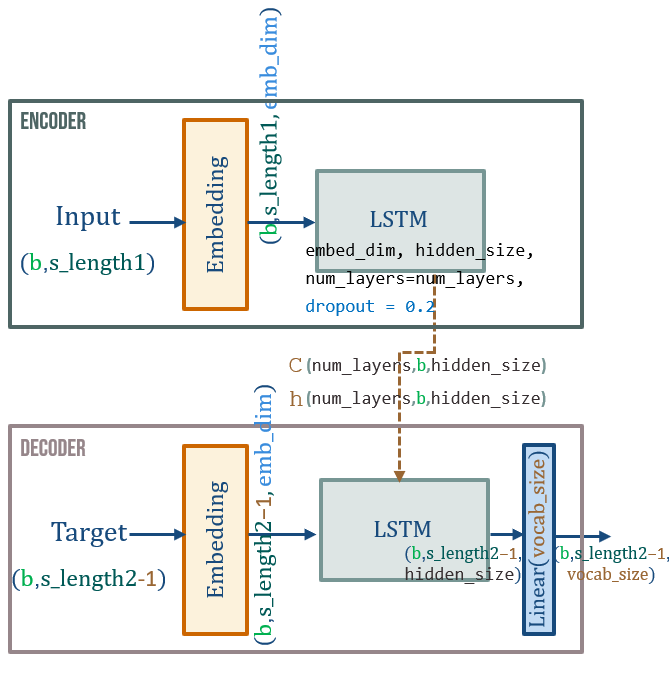

<strong><u><span>5.1/Création de la classe *Encoder*</span></u></strong>



In [ ]:
from IPython.terminal.embed import embed
class Encoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, num_layers=1):# num_layers=1 par défaut 1 neurone RNN classique
    # supposons num_layers=2 : intern 2 neurones tzid nbre de parametre (num layer tekber nbre de parametre yekber)
    #idha num_layers >1 nejmou nestaamlou dropout
        super().__init__()

        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embed_dim,padding_idx=0)

        self.lstm = nn.LSTM(input_size=embed_dim,hidden_size=hidden_size,num_layers=num_layers,dropout=0.2 if num_layers>1 else 0.0,batch_first=True)#batch_first=True obligatoire

    def forward(self, src):
        emb = self.embedding(src)

        outputs,(hidden, cell)  = self.lstm(emb) # h, c eli houma hidden w cell bech naaytoulhom baad f decoder

        # Pour ce Seq2Seq classique, le Decoder a surtout besoin de (hidden, cell).
        return (hidden, cell)

<strong><u><span>5.2/Création de la classe *Decoder*</span></u></strong>

Le Decoder reçoit des tokens français et les états `(hidden, cell)` provenant de l'Encoder. Sa dernière couche `Linear` transforme chaque état caché en scores sur **tout le vocabulaire français**.

In [ ]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, num_layers=1):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embed_dim)

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=0.2 if num_layers > 1 else 0.0,
            batch_first=True
        )

        self.fc_out = nn.Linear(hidden_size, vocab_size)

    def forward(self, tgt_in, hidden_state):

        embedded = self.embedding(tgt_in) #tgt => target

        output, hidden_state = self.lstm(
            embedded,
            hidden_state
        )

        logits = self.fc_out(output)

        return logits, hidden_state

<strong><u><span>5.3/Création de la classe *Seq2Seq*</span></u></strong>

Le modèle complet enchaîne :

1. `Encoder(src)` → `(hidden, cell)`
2. `Decoder(tgt_in, (hidden, cell))` → prédictions des mots français.

In [ ]:
class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, tgt_in):
        hidden_state = self.encoder(src)

        # appeler le Decoder avec tgt_in et hidden_state.
        logits, _ = self.decoder(tgt_in, hidden_state)

        return logits

<font color="red"><u><i>Affichage du résumé de l’architecture du modèle</i></u></font>

In [ ]:
# À exécuter une fois dans Colab si nécessaire :
!pip install -q torchinfo

In [ ]:
from torchinfo import summary

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé :", device)

vocab_en_size = len(vocab_en)
vocab_fr_size = len(vocab_fr)

encoder = Encoder(vocab_size=vocab_en_size,embed_dim=32,hidden_size=64,num_layers=2)

decoder = Decoder(vocab_size=vocab_fr_size,embed_dim=32,hidden_size=64,num_layers=2)

model = Seq2Seq(encoder, decoder).to(device)

src_demo = torch.zeros((3, 7), dtype=torch.long).to(device)
tgt_demo = torch.zeros((3, 5), dtype=torch.long).to(device)

summary(model, input_data=(src_demo, tgt_demo),col_names=("input_size", "output_size", "num_params"),device=str(device))

Device utilisé : cpu


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Seq2Seq                                  [3, 7]                    [3, 5, 66]                --
├─Encoder: 1-1                           [3, 7]                    [2, 3, 64]                --
│    └─Embedding: 2-1                    [3, 7]                    [3, 7, 32]                2,048
│    └─LSTM: 2-2                         [3, 7, 32]                [3, 7, 64]                58,368
├─Decoder: 1-2                           [3, 5]                    [3, 5, 66]                --
│    └─Embedding: 2-3                    [3, 5]                    [3, 5, 32]                2,112
│    └─LSTM: 2-4                         [3, 5, 32]                [3, 5, 64]                58,368
│    └─Linear: 2-5                       [3, 5, 64]                [3, 5, 66]                4,290
Total params: 125,186
Trainable params: 125,186
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 2.13
In

In [ ]:
print(model)

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(64, 32, padding_idx=0)
    (lstm): LSTM(32, 64, num_layers=2, batch_first=True, dropout=0.2)
  )
  (decoder): Decoder(
    (embedding): Embedding(66, 32)
    (lstm): LSTM(32, 64, num_layers=2, batch_first=True, dropout=0.2)
    (fc_out): Linear(in_features=64, out_features=66, bias=True)
  )
)


---

<strong><u><span>6/Entraînement du modèle</span></u></strong>

### Pourquoi décaler la cible ?

Si la phrase cible est :

`<sos> je suis ici <eos>`

on construit :

- `tgt_in`  : `<sos> je suis ici`
- `tgt_out` : `je suis ici <eos>`

Le Decoder apprend donc à **prédire le token suivant**.



**NB:** `CrossEntropyLoss(ignore_index=pad_id)` ignore les tokens `<pad>` lors du calcul de la perte.

In [ ]:
pad_id = vocab_fr["<pad>"]

criterion = nn.CrossEntropyLoss(ignore_index=pad_id)

optimizer = optim.Adam(model.parameters(), lr=1e-3)

<u>Gradient clipping — optionnel</u>




In [ ]:
def train(model, train_loader, val_loader, criterion, optimizer, pad_id, epochs=10):

    best_val = float("inf")

    for epoch in range(epochs):

        # =====================================================
        # 1) ENTRAÎNEMENT
        # =====================================================
        model.train()     # mode entraînement

        train_loss_sum = 0.0
        train_tokens = 0

        progress_bar = tqdm(train_loader,desc=f"Époque {epoch + 1}/{epochs}")

        for src, tgt in progress_bar:

            # Décalage de la phrase cible
            tgt_in = tgt[:, :-1] #<sos> phrase ..
            tgt_out = tgt[:, 1:]#phrase .. <eos>

            # Déplacer les données sur le GPU

            src = src.to(device)
            tgt_in = tgt_in.to(device)
            tgt_out = tgt_out.to(device)

            # Forward
            logits = model(src,tgt_in) # apres applique couche linéare logits->(b,seq length, vocab size) exple(3,5,50) prédite (3 phrases 5 mots)   (15,50)
            #target out -> (b,5)  (3,5) désiré    (15,)

            vocab_size = logits.size(-1)
            _,_, v = logits.size()
            loss = criterion(logits.reshape(-1,v),tgt_out.reshape(-1)) # loss moyenne

            optimizer.zero_grad()

            # TODO étudiant : lancer la rétropropagation
            loss.backward()

            # protection contre l'exploding gradient # doit être placer après backward() et avant optimizer.step().
            torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)# obligatoire
             # solution ll exploding gradient ||g|| = racine((dirivé erreur/derivee wx) au carré *(dirivé erreur/derivee wh) au carré* (dirivé erreur/derivee wy) au carré)

            # TODO étudiant : mise à jour des poids
            optimizer.step()

            mask = (tgt_out != pad_id)

            train_loss_sum += loss.item() * mask.sum().item()
            train_tokens += mask.sum().item()

        train_loss = train_loss_sum / train_tokens


        # =====================================================
        # 2) VALIDATION
        # =====================================================
        model.eval()

        val_loss_sum = 0.0
        val_tokens = 0

        with torch.no_grad():

            for src, tgt in val_loader:

                tgt_in =  tgt[:, :-1]
                tgt_out =  tgt[:, 1:]

                src = src.to(device)
                tgt_in = tgt_in.to(device)
                tgt_out = tgt_out.to(device)

                logits = model(src,tgt_in)

                vocab_size = logits.size(-1)

                loss = criterion(logits.reshape(-1, vocab_size),tgt_out.reshape(-1))

                mask = ( tgt_out != pad_id)

                val_loss_sum += loss.item() * mask.sum().item()
                val_tokens += mask.sum().item()

        val_loss = val_loss_sum / val_tokens
        ppl = math.exp(val_loss)

        print(f"Train Loss: {train_loss:.4f} | "f"Val Loss: {val_loss:.4f} | "f"Val PPL: {ppl:.2f}")

        if val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(),"best_seq2seq.pt")
            print("Nouveau meilleur modèle sauvegardé.")

### Lancement de l'entraînement



In [ ]:
train(model,train_loader, val_loader, criterion, optimizer, pad_id, epochs=10)

Époque 1/10: 100%|██████████| 8/8 [00:00<00:00, 154.10it/s]


Train Loss: 4.1903 | Val Loss: 4.1808 | Val PPL: 65.42
Nouveau meilleur modèle sauvegardé.


Époque 2/10: 100%|██████████| 8/8 [00:00<00:00, 126.78it/s]


Train Loss: 4.1299 | Val Loss: 4.1469 | Val PPL: 63.24
Nouveau meilleur modèle sauvegardé.


Époque 3/10: 100%|██████████| 8/8 [00:00<00:00, 164.28it/s]


...

Train Loss: 3.0770 | Val Loss: 4.4287 | Val PPL: 83.83


Époque 9/10: 100%|██████████| 8/8 [00:00<00:00, 166.19it/s]


Train Loss: 3.0220 | Val Loss: 4.4610 | Val PPL: 86.57


Époque 10/10: 100%|██████████| 8/8 [00:00<00:00, 170.21it/s]

Train Loss: 2.9529 | Val Loss: 4.5140 | Val PPL: 91.29


<strong><u><span>7/translate_sentence(model, src_tensor, max_len)</span></u></strong>

**<u>Traduction d'une phrase</u>**

Pendant l'inférence, nous ne disposons plus de la vraie phrase française.

Le Decoder fonctionne donc **token par token** :

1. il commence avec `<sos>` ;
2. il prédit le prochain token ;
3. ce token devient l'entrée suivante ;
4. on s'arrête lorsque `<eos>` est prédit ou lorsque `max_len` est atteint.

In [ ]:
@torch.no_grad() #docérateur definir .eval et no_grad de façon auto
def translate_sentence(model, src_tensor, max_len=15):

    # États initiaux du Decoder provenant de l'Encoder
    hidden_state = model.encoder(src_tensor)# mode inférence  #Memory
    # state_dict enregistre uniquement les poids

    # Premier token : <sos>
    current_token = torch.tensor([[vocab_fr["<sos>"]]],dtype=torch.long,device=device)#tgt


    for _ in range(max_len):

        logits, hidden_state = model.decoder(current_token, hidden_state)# logits.size()=[1,1,vocab_size] puis [1,2,vocab_size] puis ...
        # Scores du dernier pas temporel
        next_token = logits[:, -1, :].argmax(dim=-1).unsqueeze(0)# next_token.size()=[1,1]
        #  chaque mots liées par l'autre donc une fois ghlot f loula naamlou liaison b classe désiré non prédite
        current_token  = torch.cat([current_token, next_token], dim=1)

        if next_token == vocab_fr["<eos>"]:
            break


    return current_token.squeeze().tolist()#squeeze()=supprime toutes les dims=1 dans notre cas retourne de type 1D


<strong><u><span>8/tokens_to_sentence(tokens, vocab)</span></u></strong>

**<u>Transformation en phrase</u>**

Cette fonction :

- inverse le vocabulaire `{mot: id}` → `{id: mot}` ;
- ignore `<sos>`, `<eos>` et `<pad>` ;
- reconstruit une phrase lisible.

In [ ]:
def tokens_to_sentence(tokens, vocab):
    # Inverser le dictionnaire {mot:id} -> {id:mot}
    id2word = {idx: word for word, idx in vocab.items()}

    words = []

    for tok in tokens:
        word = id2word.get(tok, "<unk>")

        if word in ["<sos>", "<eos>", "<pad>"]:
            continue

        words.append(word)

    # assembler les mots avec un espace
    return " ".join(words)


<strong><u><span>9/Test du modèle</span></u></strong>

Testons maintenant une phrase anglaise jamais fournie directement au Decoder.

In [ ]:
sentence= "you are good"

indices=text_to_indices(sentence, vocab_en, max_len=7)

src= torch.tensor([indices]).to(device) #Liste de listes→Tensor2d

tokens_traduits= translate_sentence(model, src)

phrase= tokens_to_sentence (tokens_traduits, vocab_fr)


print("EN :", sentence)
print("FR :", phrase)


EN : you are good
FR : j'ai


<strong><u><span>Récapitulatif</span></u></strong>

| Élément | Rôle |
|---|---|
| `build_vocab(...)` | construire le dictionnaire mot → ID |
| `text_to_indices(...)` | transformer une phrase en séquence d'IDs |
| `Embedding` | transformer chaque ID en vecteur dense |
| `Encoder LSTM` | lire la phrase source et produire `(hidden, cell)` |
| `Decoder LSTM` | générer la séquence cible |
| `tgt[:, :-1]` | entrée du Decoder pendant l'entraînement |
| `tgt[:, 1:]` | mots que le Decoder doit prédire |
| `CrossEntropyLoss` | mesurer l'erreur de prédiction |
| `loss.backward()` | calculer les gradients |
| `clip_grad_norm_` | limiter la norme globale des gradients |
| `optimizer.step()` | mettre à jour les poids |
| `<sos>` | démarrer la génération |
| `<eos>` | arrêter la génération |

